# Dataset and Dataloaders

> Datasets and Dataloaders


- skip_showdoc: true
- skip_exec: true

In [ ]:
from torchvision import datasets

In [ ]:
datasets.__all__


('LSUN',
 'LSUNClass',
 'ImageFolder',
 'DatasetFolder',
 'FakeData',
 'CocoCaptions',
 'CocoDetection',
 'CIFAR10',
 'CIFAR100',
 'EMNIST',
 'FashionMNIST',
 'QMNIST',
 'MNIST',
 'KMNIST',
 'StanfordCars',
 'STL10',
 'SUN397',
 'SVHN',
 'PhotoTour',
 'SEMEION',
 'Omniglot',
 'SBU',
 'Flickr8k',
 'Flickr30k',
 'Flowers102',
 'VOCSegmentation',
 'VOCDetection',
 'Cityscapes',
 'ImageNet',
 'Caltech101',
 'Caltech256',
 'CelebA',
 'WIDERFace',
 'SBDataset',
 'VisionDataset',
 'USPS',
 'Kinetics',
 'HMDB51',
 'UCF101',
 'Places365',
 'Kitti',
 'INaturalist',
 'LFWPeople',
 'LFWPairs',
 'KittiFlow',
 'Sintel',
 'FlyingChairs',
 'FlyingThings3D',
 'HD1K',
 'Food101',
 'DTD',
 'FER2013',
 'GTSRB',
 'CLEVRClassification',
 'OxfordIIITPet',
 'PCAM',
 'Country211',
 'FGVCAircraft',
 'EuroSAT',
 'RenderedSST2',
 'Kitti2012Stereo',
 'Kitti2015Stereo',
 'CarlaStereo',
 'Middlebury2014Stereo',
 'CREStereo',
 'FallingThingsStereo',
 'SceneFlowStereo',
 'SintelStereo',
 'InStereo2k',
 'ETH3DStereo',


## MNIST

In [ ]:
from torchvision import datasets, transforms
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
import numpy as np

In [ ]:
torch.cuda.is_available() 

True

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:

path = './Data'
# Define transforms for preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),          # Convert image to tensor
    transforms.Normalize((0.5,), (0.5,))  # Normalize image pixel values to range [-1, 1]
])

# Define batch size for data loader
batch_size = 64

# Create train and test datasets
train_dataset = datasets.MNIST(root=path, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root=path, train=False, download=True, transform=transform)

# Create train and test data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
len(train_dataset), len(test_dataset)

(60000, 10000)

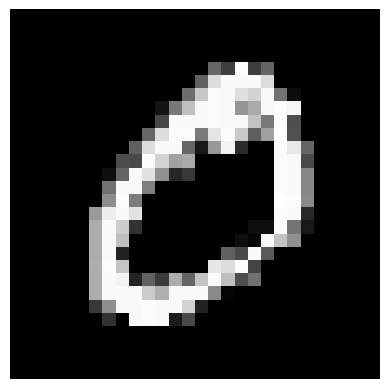

In [ ]:
image, label = train_dataset[1]
plt.imshow(transforms.ToPILImage()(image), cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
examples = iter(train_loader)

In [ ]:
images, labels = next(examples)
images.shape, labels.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64]))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.ceil(np.sqrt(len(images))))
    ncols = int(np.ceil(len(images)/nrows))
        
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 12),  **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.1, hspace=0.3)
    for i, ax in enumerate(axes.flat):
        # Convert image to numpy array and adjust pixel values
        img_np = images[i].numpy().transpose((1, 2, 0))
        img_np = (img_np + 1) / 2  # Adjust pixel values to range [0, 1]
        
        # Display image
        ax.imshow(img_np, cmap='gray')
        ax.axis('off')
        ax.set_title(f'Label: {labels[i]}')
    plt.show()

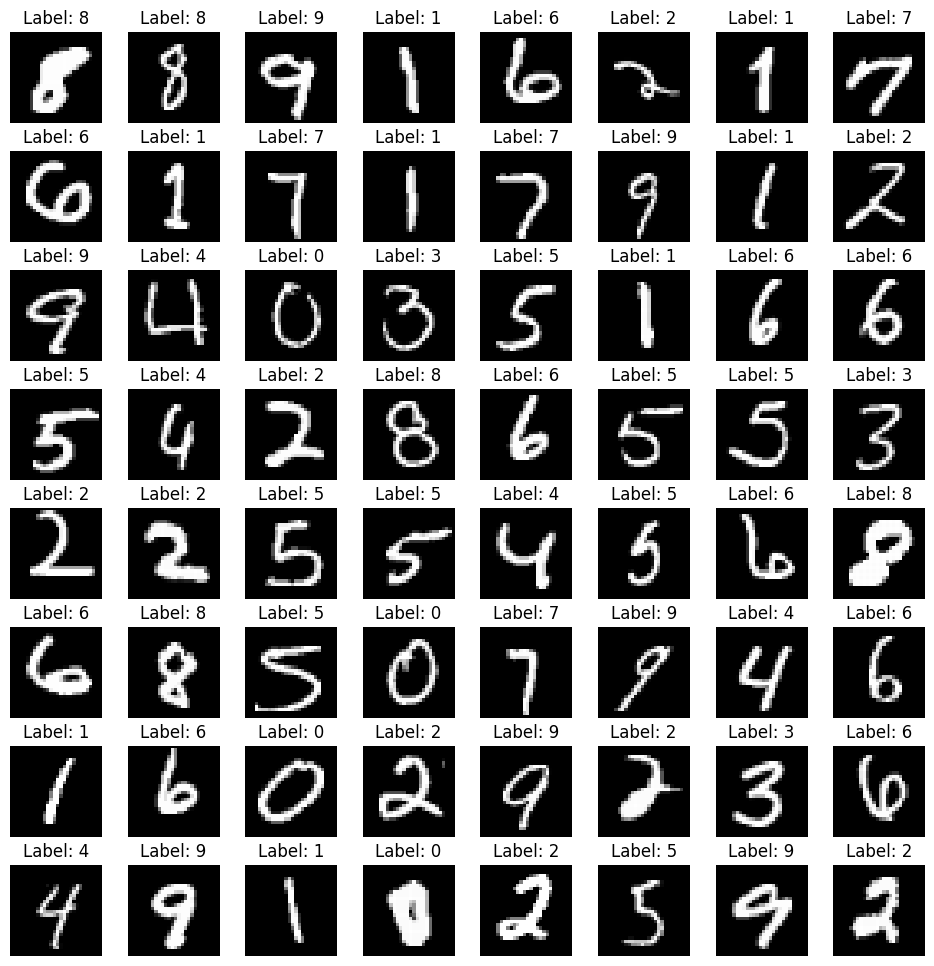

In [ ]:
show_images(images, labels)

## Cifar10

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [ ]:
torch.cuda.is_available() 

True

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
path = 'Data'

# Define transforms for preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),                       # Convert image to tensor
    transforms.Normalize((0.5, 0.5, 0.5),       # Normalize image pixel values to range [-1, 1]
                         (0.5, 0.5, 0.5))
])

# Define batch size for data loader


# Create train and test datasets
train_dataset = datasets.CIFAR10(root=path, train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root=path, train=False, download=True, transform=transform)

# Create train and test data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Files already downloaded and verified
Files already downloaded and verified


In [ ]:
len(train_dataset), len(test_dataset)

(50000, 10000)

In [ ]:
images, labels = train_dataset[1]

In [ ]:
type(labels)

int

In [ ]:
classes = train_dataset.class_to_idx

In [ ]:
classes = list(train_dataset.class_to_idx)

In [ ]:
list(classes)

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.ceil(np.sqrt(len(images))))
    ncols = int(np.ceil(len(images)/nrows))
        
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 12),  **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.3, hspace=0.3)
    for i, ax in enumerate(axes.flat):
        # Convert image to numpy array and adjust pixel values
        img_np = images[i].numpy().transpose((1, 2, 0))
        img_np = (img_np + 1) / 2  # Adjust pixel values to range [0, 1]
        
        # Display image
        ax.imshow(img_np)
        ax.axis('off')
        ax.set_title(f' {classes[labels[i]]}')
    plt.show()

In [ ]:
# Get a batch of images and labels from the data loader
examples = iter(train_loader)
images, labels = next(examples)

In [ ]:
type(labels)

torch.Tensor

In [ ]:
images.shape, labels.shape


(torch.Size([64, 3, 32, 32]), torch.Size([64]))

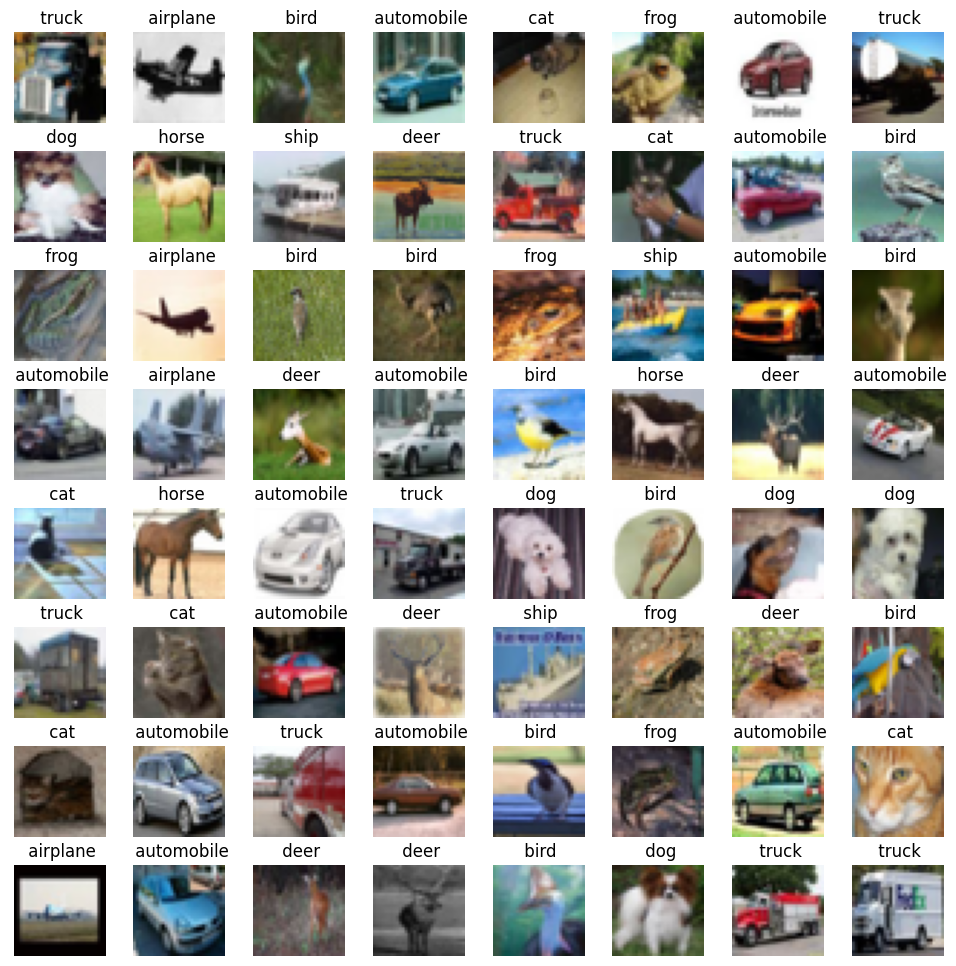

In [ ]:
# Display the images
show_images(images, labels)

## Imagenette

In [ ]:
from torchvision.datasets import ImageFolder
from tqdm import tqdm

In [ ]:
# Define transformation to convert images to tensors
transform = transforms.Compose([
    transforms.Resize(256),     # Resize images to 256x256
    transforms.CenterCrop(224), # Crop the center 224x224 region
    transforms.ToTensor()       # Convert images to PyTorch tensors
])

# Load Imagenette dataset
imagenette_dataset = ImageFolder(root='Data/Imagenette_depth/imagenette2', transform=transform)
imagenette_dataset

Dataset ImageFolder
    Number of datapoints: 13394
    Root location: Data/Imagenette_depth/imagenette2
    StandardTransform
Transform: Compose(
               Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
               CenterCrop(size=(224, 224))
               ToTensor()
           )

In [ ]:
# Calculate mean and standard deviation
loader = torch.utils.data.DataLoader(imagenette_dataset, batch_size=128, shuffle=False)
mean_list = []
std_list = []

for image, label in tqdm(loader):
    mean = image.mean(dim=[0, 2, 3])  # Calculate mean across batch, height, and width
    std = image.std(dim=[0, 2, 3])    # Calculate standard deviation across batch, height, and width
    mean_list.append(mean)
    std_list.append(std)


100%|█████████████████████████████████████████████████████████████████████████████████| 105/105 [03:44<00:00,  2.14s/it]


In [ ]:
mean_tensor = torch.stack(mean_list)
std_tensor = torch.stack(std_list)

In [ ]:
mean_tensor.mean(dim=[0]), std_tensor.mean(dim=[0])

(tensor([0.4654, 0.4544, 0.4252]), tensor([0.2761, 0.2679, 0.2839]))

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

from tqdm import tqdm 
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Define the transformations to apply to the images
transform = transforms.Compose([
    transforms.Resize((375, 500)),
    transforms.ToTensor(),
])

# Download and load the Imagenette dataset
train_dataset = datasets.Imagenette(root='Data',
                                    split='train',
                                    # download=True,
                                    transform=transform,
                                    )


# Download and load the Imagenette dataset
test_dataset = datasets.Imagenette(root='Data',
                                  split='val',
                                  # download=True,
                                  transform=transform,
                                 )

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
train_dataset.__dict__.keys()

dict_keys(['root', 'transform', 'target_transform', 'transforms', '_split', '_size', '_url', '_md5', '_size_root', '_image_root', 'wnids', 'wnid_to_idx', 'classes', 'class_to_idx', '_samples'])

In [ ]:
train_dataset.classes

[('tench', 'Tinca tinca'),
 ('English springer', 'English springer spaniel'),
 ('cassette player',),
 ('chain saw', 'chainsaw'),
 ('church', 'church building'),
 ('French horn', 'horn'),
 ('garbage truck', 'dustcart'),
 ('gas pump', 'gasoline pump', 'petrol pump', 'island dispenser'),
 ('golf ball',),
 ('parachute', 'chute')]

In [ ]:
len(train_dataset), len(test_dataset)

(9469, 3925)

In [ ]:
images, labels = train_dataset[10]
images.shape

torch.Size([3, 375, 500])

In [ ]:

# Define a function to display images
def show_image(dataset):
    # Access an image and its label from the dataset
    image, label = dataset
    
    # Convert the image tensor to a NumPy array
    image_np = image.numpy().transpose((1, 2, 0))

    # Display the image using Matplotlib
    plt.imshow(image_np)
    plt.axis('off')
    plt.title(f' {train_dataset.classes[label][0]}')
    plt.show()
    
   
# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.ceil(np.sqrt(len(images))))
    ncols = int(np.ceil(len(images)/nrows))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 12),  **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.3, hspace=0.3)
    for i, ax in enumerate(axes.flat):
        # Convert image to numpy array and adjust pixel values
        img_np = images[i].numpy().transpose((1, 2, 0))
        
        # Display image
        ax.imshow(img_np)
        ax.axis('off')
        ax.set_title(f' {train_dataset.classes[labels[i]][0]}')
    plt.show()

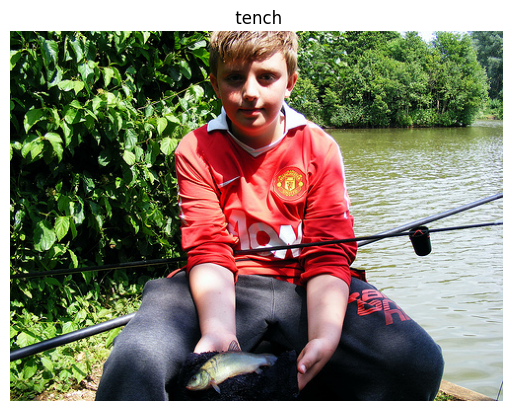

In [ ]:
show_image(train_dataset[2])

In [ ]:
# Get a batch of images and labels from the data loader
examples = iter(train_loader)
images, labels = next(examples)

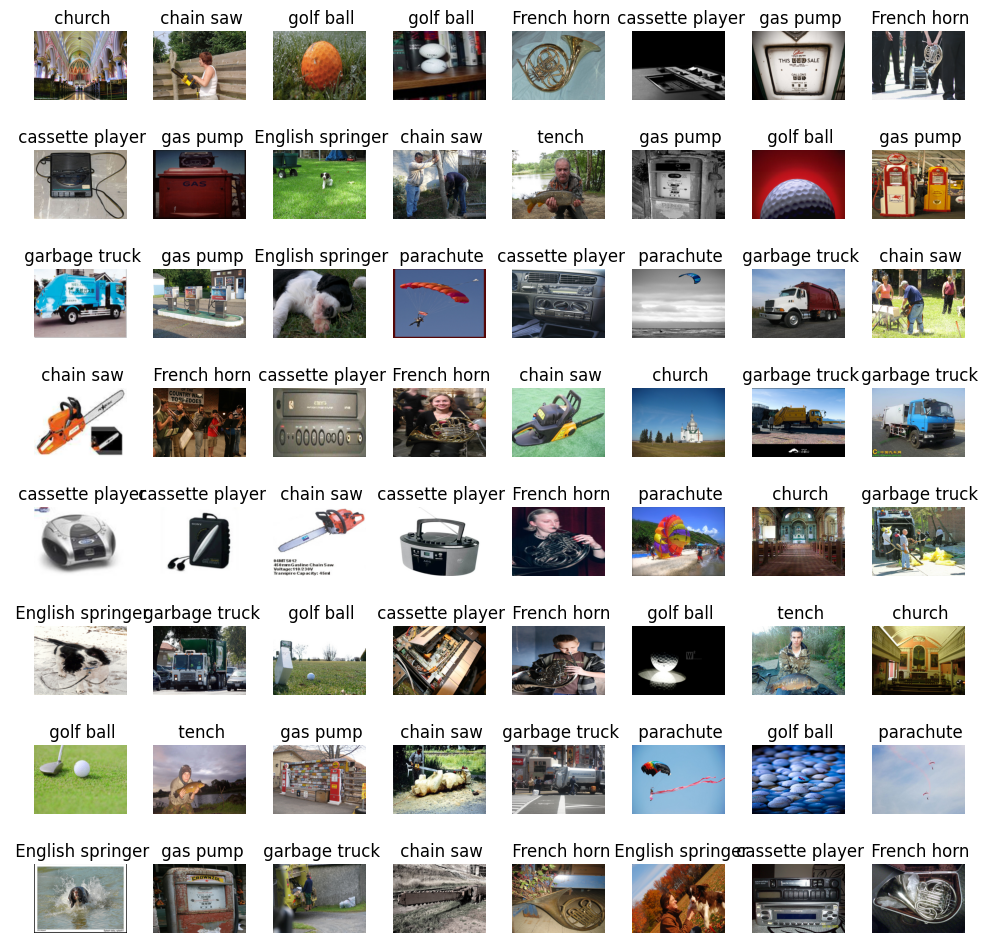

In [ ]:
show_images(images, labels)

## Country211

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms, datasets, utils
from torch.utils.data import DataLoader, Dataset, random_split

import torch
import os
from PIL import Image

from tqdm import tqdm 
import matplotlib.pyplot as plt
import timm
import numpy as np
from datetime import datetime

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [ ]:
from torchvision import transforms

# Define transforms to apply to the images
transform_default = transforms.Compose([
    transforms.Resize((200, 300)),  # Resize images to a fixed size
    transforms.ToTensor(),  # Convert images to PyTorch tensors
    # Add more transformations as needed (e.g., normalization)
])

# Path to the root directory of the dataset
root_dir = 'Data'

# Create datasets
train_dataset = datasets.Country211(root_dir,
                                   split = 'train',
                                    transform=transform_default,
                                    download = False)
val_dataset = datasets.Country211(root_dir,
                                   split = 'valid',
                                    transform=transform_default,
                                    download = False)
test_dataset = datasets.Country211(root_dir,
                                   split = 'test',
                                    transform=transform_default,
                                    download = False)

In [ ]:
images, label = train_dataset[1000]


In [ ]:
images.shape

torch.Size([3, 200, 300])

In [ ]:
len(train_dataset.classes)

211

In [ ]:
len(train_dataset), len(val_dataset), len(test_dataset)

(31650, 10550, 21100)

In [ ]:
train_dataset

Dataset Country211
    Number of datapoints: 31650
    Root location: Data
    StandardTransform
Transform: Compose(
               Resize(size=(200, 300), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

In [ ]:
train_dataset.__dict__.keys()

dict_keys(['_split', 'root', '_base_folder', 'transform', 'target_transform', 'transforms', 'loader', 'extensions', 'classes', 'class_to_idx', 'samples', 'targets', 'imgs'])

In [ ]:
# Define a function to display images
def show_image(dataset):
    # Access an image and its label from the dataset
    image, label = dataset
    # Convert the image tensor to a NumPy array
    image_np = image.numpy().transpose((1, 2, 0))

    # Display the image using Matplotlib
    plt.imshow(image_np.clip(0,1))
    plt.axis('off')
    plt.title(f' {train_dataset.classes[label]}')
    plt.show()
    
   
# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.ceil(np.sqrt(len(images))))
    ncols = int(np.ceil(len(images)/nrows))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 12),  **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.3, hspace=0.3)
    for ax, image, label in zip(axes.flat, images, labels):
        # Convert image to numpy array and adjust pixel values
        img_np = image.numpy().transpose((1, 2, 0))
        
        # Display image
        ax.imshow(img_np.clip(0,1))
        ax.axis('off')
        ax.set_title(f' {train_dataset.classes[label]}')
    for ax in axes.flat[len(images):]:
        ax.axis('off')
        
    plt.show()

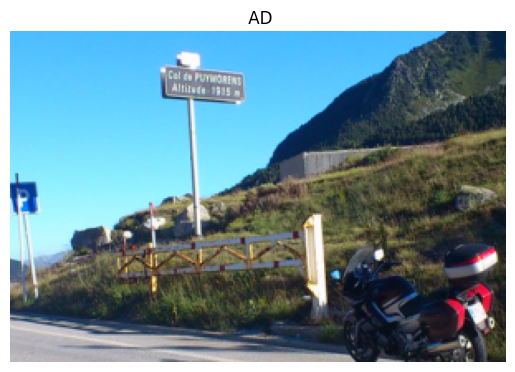

In [ ]:
show_image(train_dataset[6])

In [ ]:
def loaders(batch_size):

    train_loader = DataLoader(train_dataset,
                              batch_size=batch_size,
                              shuffle=True,
                              num_workers=8)
    val_loader = DataLoader(val_dataset,
                             batch_size=batch_size,
                             shuffle=True, 
                             num_workers=8)
    test_loader = DataLoader(test_dataset,
                              batch_size=batch_size,
                              shuffle=True,
                              num_workers=8)

    # dataloaders = {'train': train_loader, 'val': test_loader}
    # dataset_sizes = {'train': len(train_dataset), 'val': len(test_dataset) }
    return train_loader, val_loader, test_loader

In [ ]:
batch_size = 32
train_loader, val_loader, test_loader = loaders(batch_size)

In [ ]:
# Get a batch of images and labels from the data loader
examples = iter(test_loader)
images, labels = next(examples)
# ############## TENSORBOARD ########################
# img_grid = utils.make_grid(images)

# writer.add_image('Imagenette', img_grid)
# writer.flush()
# #sys.exit()
# ###################################################

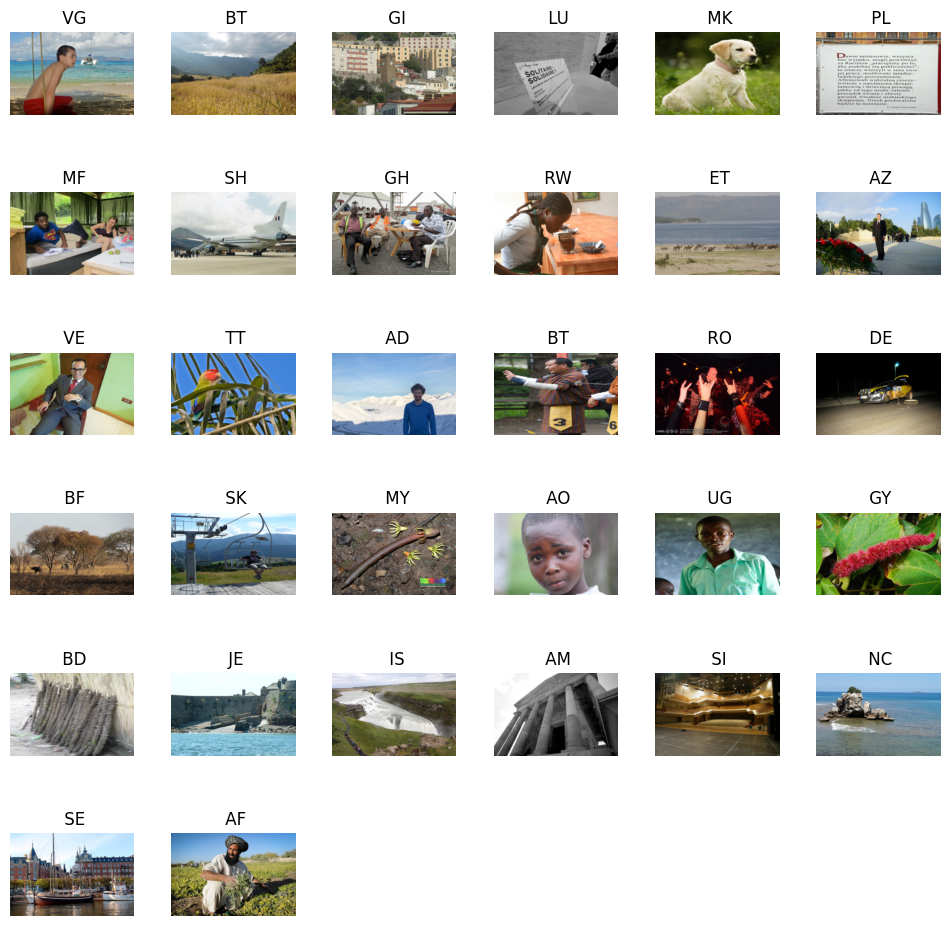

In [ ]:
show_images(images, labels)

In [ ]:
def find_mean_std(loader):
    mean_list = []
    std_list = []
    for images, label in tqdm(loader):
        mean, std = images.mean([0,2,3]), images.std([0,2,3])  
        mean_list.append(mean)
        std_list.append(std)
    
    mean_tensor = torch.stack(mean_list)
    std_tensor = torch.stack(std_list)
    return mean_tensor.mean(dim=[0]), std_tensor.mean(dim=[0])

In [ ]:
train_norm = find_mean_std(train_loader)

100%|█████████████████████████████████████████████████████████████████████████████████| 990/990 [00:32<00:00, 30.55it/s]


(tensor([0.4571, 0.4504, 0.4209]), tensor([0.2706, 0.2646, 0.2857]))

In [ ]:
find_mean_std(val_loader)

100%|█████████████████████████████████████████████████████████████████████████████████| 330/330 [00:11<00:00, 29.80it/s]


(tensor([0.4587, 0.4514, 0.4219]), tensor([0.2706, 0.2647, 0.2852]))

In [ ]:
find_mean_std(test_loader)

100%|█████████████████████████████████████████████████████████████████████████████████| 660/660 [00:25<00:00, 26.12it/s]


(tensor([0.4578, 0.4512, 0.4218]), tensor([0.2702, 0.2642, 0.2856]))

## Kitti

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, datasets
from torchvision.transforms import ToPILImage, v2
from torch.utils.data import DataLoader

from tqdm import tqdm 
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [ ]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook

# Create a histogram plot
output_notebook()

Loading BokehJS ...

In [ ]:
class Kitti_v2(datasets.Kitti):
    def __init__(self, *args, **kwargs):
        super(Kitti_v2, self).__init__(*args, **kwargs)

In [ ]:
path = './Data'
batch_size = 16

# Define transforms
# Define transforms for the dataset
transform2 = v2.Compose(
    [
        v2.ToImage(),
        # v2.Resize(size = desired_size),  # Resize image
        v2.RandomPhotometricDistort(p=0.2),
        # v2.RandomZoomOut(fill={tv_tensors.Image: (123, 117, 104), "others": 0}),
        # # v2.RandomIoUCrop(),
        v2.RandomHorizontalFlip(p=0.4),
        # # v2.SanitizeBoundingBoxes(),
        v2.ToDtype(torch.float32, scale=True),
    ]
)

In [ ]:
# Load KITTI train dataset
train_dataset = Kitti_v2(root=path, train='true', download=True, transform=transform2)

# Load KITTI test dataset
test_dataset = Kitti_v2(root=path, train='false', download=True, transform=transform2)

In [ ]:
sample = train_dataset[1000]
img, target = sample
print(f"{type(img) = }\n{type(target) = }")

type(img) = <class 'torchvision.tv_tensors._image.Image'>
type(target) = <class 'list'>


In [ ]:
train_dataset2 = datasets.wrap_dataset_for_transforms_v2(train_dataset, target_keys=("boxes", "labels"))

test_dataset2 = datasets.wrap_dataset_for_transforms_v2(test_dataset, target_keys=("boxes", "labels"))

In [ ]:
sample = train_dataset2[1000]
img, target = sample
print(f"{type(img) = }\n{type(target) = }\n{target.keys() = }")
print(f"{type(target['boxes']) = }\n{type(target['labels']) = }")

type(img) = <class 'torchvision.tv_tensors._image.Image'>
type(target) = <class 'dict'>
target.keys() = dict_keys(['boxes', 'labels'])
type(target['boxes']) = <class 'torchvision.tv_tensors._bounding_boxes.BoundingBoxes'>
type(target['labels']) = <class 'torch.Tensor'>


In [ ]:
batch_size = 8

train_loader = DataLoader(train_dataset2,
                          batch_size=batch_size,
                          shuffle=True,
                          collate_fn=lambda batch: tuple(zip(*batch)),
                          num_workers = 8)

# Create DataLoader for test dataset
test_loader = DataLoader(test_dataset2,
                         batch_size=batch_size,
                         shuffle=False,
                         collate_fn=lambda batch: tuple(zip(*batch)),
                         num_workers = 8)

In [ ]:
train_dataset

Dataset Kitti_v2
    Number of datapoints: 7481
    Root location: ./Data

In [ ]:
len(train_dataset)

7481

In [ ]:
image, targets = train_dataset[2]
type(targets)

list

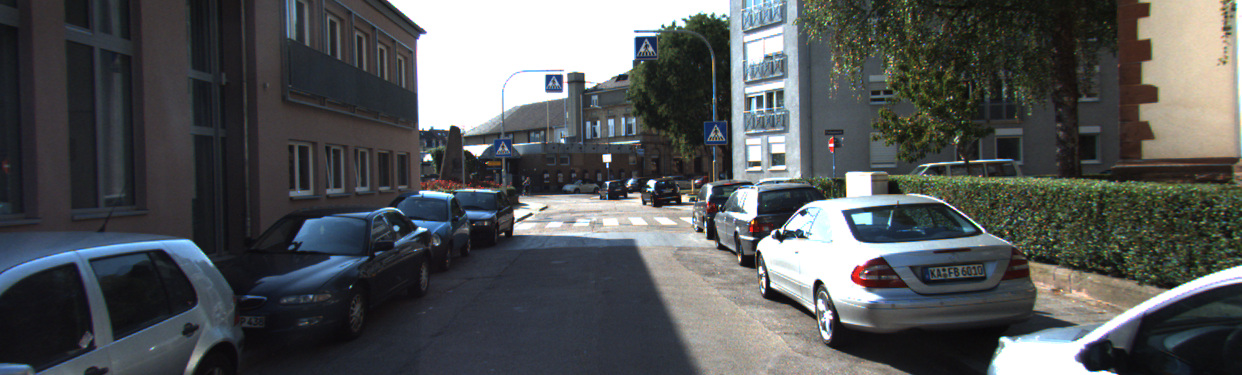

In [ ]:
image

In [ ]:
car_types = ['Car', 'Van', 'DontCare',
             'Cyclist', 'Pedestrian', 'Truck',
             'Tram', 'Misc', 'Person_sitting']

In [ ]:
def cv2_show(image_np, label):
    image_cv2 = cv2.cvtColor((image_np * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
    if 'scores' in label:
        for bbox, item, score in zip(label['boxes'], label['labels'], label['scores']):
            if score > 0.2:
                cv2.rectangle(image_cv2,
                              (int(bbox[0]), int(bbox[1])), (int(bbox[2]), int(bbox[3])),
                              (0, 255, 0), 2)
            
                # Display the label
                font = cv2.FONT_HERSHEY_SIMPLEX
                cv2.putText(image_cv2, str(item),
                            (int(bbox[0]), int(bbox[1]) - 10),
                            font, 0.5, (0, 255, 0), 2, cv2.LINE_AA)
    else:
        for bbox, item in zip(label['boxes'], label['labels']):
            # Draw the bounding box
            cv2.rectangle(image_cv2,
                          (int(bbox[0]), int(bbox[1])), (int(bbox[2]), int(bbox[3])),
                          (0, 255, 0), 2)
        
            # Display the label
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(image_cv2, str(item),
                        (int(bbox[0]), int(bbox[1]) - 10),
                        font, 0.5, (0, 255, 0), 2, cv2.LINE_AA)

    # Convert the image back to RGB format for display with Matplotlib
    image_rgb = cv2.cvtColor(image_cv2, cv2.COLOR_BGR2RGB)
    
    return image_rgb

def show_image(kitti_dataset):
    # Access an image and its label from the dataset
    image, label = kitti_dataset
    
    # Convert the image tensor to a NumPy array
    image_np = image.numpy().transpose((1, 2, 0))
    image_rgb = cv2_show(image_np, label)
    # Display the image using Matplotlib
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.sqrt(len(images)))
    ncols = int(np.floor(len(images)/nrows))
        
    fig, axes = plt.subplots(nrows, ncols, **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.01, hspace=0.01)

    # Display the image using Matplotlib
    for ax, image, label in zip(axes.flat, images, labels):
        # Convert image to numpy array and adjust pixel values
        image_np = image.numpy().transpose((1, 2, 0))
        image_rgb = cv2_show(image_np, label)
        
        # Display image
        ax.imshow(image_rgb)
        ax.axis('off')

    for ax in axes.flat[len(images):]:
        ax.axis('off')
    plt.show()

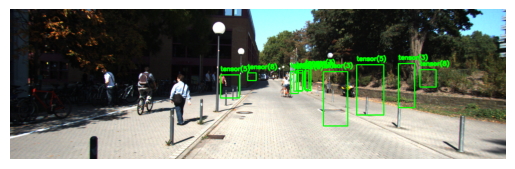

In [ ]:
image, label = train_dataset2[18]
show_image(train_dataset2[18])

### Iter

In [ ]:
# Get a batch of images and labels from the data loader
examples = iter(train_loader)
images, labels = next(examples)


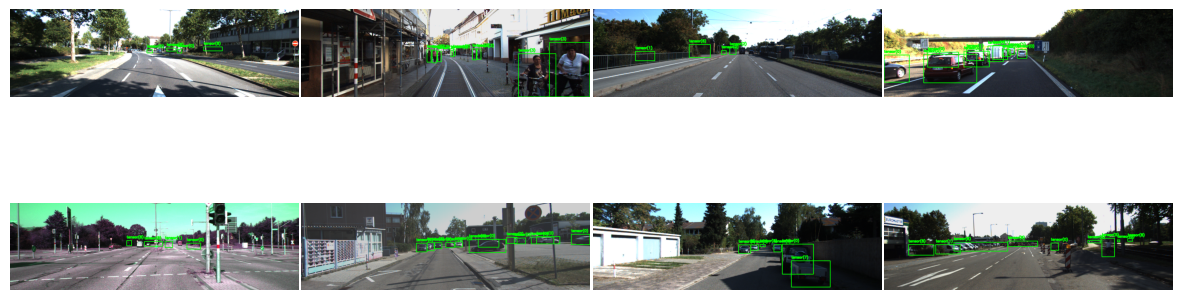

In [ ]:
show_images(images, labels, figsize=(15, 5))

## COCO

### Data download

In [ ]:
import fiftyone as fo
import fiftyone.zoo as foz

#
# Only the required images will be downloaded (if necessary).
# By default, only detections are loaded
#

In [ ]:
dataset = foz.load_zoo_dataset(
    name="coco-2017",
    dataset_dir= "Data/coco",
    splits=["validation","train"],
    classes=["person", "car"],
    max_samples=50,
)

Found annotations at 'Data/coco/raw/instances_val2017.json'
Sufficient images already downloaded
Existing download of split 'validation' is sufficient
Found annotations at 'Data/coco/raw/instances_train2017.json'
Sufficient images already downloaded
Existing download of split 'train' is sufficient
Loading 'coco-2017' split 'validation'
 100% |███████████████████| 50/50 [304.1ms elapsed, 0s remaining, 164.4 samples/s]     
Loading 'coco-2017' split 'train'
 100% |███████████████████| 50/50 [291.6ms elapsed, 0s remaining, 171.5 samples/s]     
Dataset 'coco-2017-validation-train-50' created


In [ ]:
classes = dataset.default_classes

In [ ]:
# Visualize the dataset in the FiftyOne App
session = fo.launch_app(dataset)


Welcome to

███████╗██╗███████╗████████╗██╗   ██╗ ██████╗ ███╗   ██╗███████╗
██╔════╝██║██╔════╝╚══██╔══╝╚██╗ ██╔╝██╔═══██╗████╗  ██║██╔════╝
█████╗  ██║█████╗     ██║    ╚████╔╝ ██║   ██║██╔██╗ ██║█████╗
██╔══╝  ██║██╔══╝     ██║     ╚██╔╝  ██║   ██║██║╚██╗██║██╔══╝
██║     ██║██║        ██║      ██║   ╚██████╔╝██║ ╚████║███████╗
╚═╝     ╚═╝╚═╝        ╚═╝      ╚═╝    ╚═════╝ ╚═╝  ╚═══╝╚══════╝ v0.23.8

If you're finding FiftyOne helpful, here's how you can get involved:

|
|  ⭐⭐⭐ Give the project a star on GitHub ⭐⭐⭐
|  https://github.com/voxel51/fiftyone
|
|  🚀🚀🚀 Join the FiftyOne Slack community 🚀🚀🚀
|  https://slack.voxel51.com
|



In [ ]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook

# Create a histogram plot
output_notebook()

Loading BokehJS ...

### Dataset and DataLoaders

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import transforms, datasets
from torchvision.transforms import ToPILImage, v2
from torch.utils.data import DataLoader

from tqdm import tqdm 
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [ ]:
classes = ['0', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus','train', 
           'truck', 'boat', 'traffic light', 'fire hydrant', '12', 'stop sign',
           'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
           'elephant', 'bear', 'zebra', 'giraffe', '26', 'backpack', 'umbrella', '29',
           '30', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard',
           'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard',
           'surfboard', 'tennis racket', 'bottle', '45', 'wine glass', 'cup', 'fork',
           'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange',
           'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch',
           'potted plant', 'bed', '66', 'dining table', '68', '69', 'toilet', '71',
           'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave',
           'oven', 'toaster', 'sink', 'refrigerator', '83', 'book', 'clock', 'vase',
           'scissors', 'teddy bear', 'hair drier', 'toothbrush']

In [ ]:
train_path = './Data/coco/train'
val_path = './Data/coco/validation'

# Define transforms
# Define transforms for the dataset
transform2 = v2.Compose(
    [
        v2.ToImage(),
        # v2.Resize(size = desired_size),  # Resize image
        # v2.RandomPhotometricDistort(p=0.2),
        # v2.RandomZoomOut(fill={tv_tensors.Image: (123, 117, 104), "others": 0}),
        # # v2.RandomIoUCrop(),
        # v2.RandomHorizontalFlip(p=0.4),
        # # v2.SanitizeBoundingBoxes(),
        v2.ToDtype(torch.float32, scale=True),
    ]
)

In [ ]:
# Load KITTI train dataset
train_dataset = datasets.CocoDetection(root=f'{train_path}/data',
                              annFile=f'{train_path}/labels.json', 
                              transform = transform2)

# Load KITTI test dataset
test_dataset = datasets.CocoDetection(root=f'{val_path}/data',
                            annFile=f'{val_path}/labels.json',
                            transform=transform2)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


In [ ]:
sample = train_dataset[49]
img, target = sample
print(f"{type(img) = }\n{type(target) = }")

type(img) = <class 'torchvision.tv_tensors._image.Image'>
type(target) = <class 'list'>


In [ ]:
train_dataset2 = datasets.wrap_dataset_for_transforms_v2(train_dataset)

test_dataset2 = datasets.wrap_dataset_for_transforms_v2(test_dataset)

In [ ]:
len(train_dataset2), len(test_dataset2)

(50, 50)

In [ ]:
batch_size = 2

train_loader = DataLoader(train_dataset2,
                          batch_size=batch_size,
                          shuffle=True,
                          collate_fn=lambda batch: tuple(zip(*batch)),
                          num_workers = 8)

# Create DataLoader for test dataset
test_loader = DataLoader(test_dataset2,
                         batch_size=batch_size,
                         shuffle=False,
                         collate_fn=lambda batch: tuple(zip(*batch)),
                         num_workers = 8)

In [ ]:
sample = train_dataset2[10]
img, target = sample
print(f"{type(img) = }\n{type(target) = }\n{target.keys() = }")
print(f"{type(target['boxes']) = }\n{type(target['labels']) = }")

type(img) = <class 'torchvision.tv_tensors._image.Image'>
type(target) = <class 'dict'>
target.keys() = dict_keys(['image_id', 'boxes', 'labels'])
type(target['boxes']) = <class 'torchvision.tv_tensors._bounding_boxes.BoundingBoxes'>
type(target['labels']) = <class 'torch.Tensor'>


In [ ]:
def cv2_show(image_np, label):
    image_cv2 = cv2.cvtColor((image_np * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
    if 'scores' in label:
        for bbox, item, score in zip(label['boxes'], label['labels'], label['scores']):
            if score > 0.2:
                cv2.rectangle(image_cv2,
                              (int(bbox[0]), int(bbox[1])), (int(bbox[2]), int(bbox[3])),
                              (0, 255, 0), 2)
            
                # Display the label
                font = cv2.FONT_HERSHEY_SIMPLEX
                cv2.putText(image_cv2, str(item),
                            (int(bbox[0]), int(bbox[1]) - 10),
                            font, 0.5, (0, 255, 0), 2, cv2.LINE_AA)
    else:
        for bbox, item in zip(label['boxes'], label['labels']):
            # Draw the bounding box
            cv2.rectangle(image_cv2,
                          (int(bbox[0]), int(bbox[1])), (int(bbox[2]), int(bbox[3])),
                          (0, 255, 0), 2)
        
            # Display the label
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(image_cv2, classes[item],
                        (int(bbox[0]), int(bbox[1]) - 10),
                        font, 0.5, (0, 255, 0), 2, cv2.LINE_AA)

    # Convert the image back to RGB format for display with Matplotlib
    image_rgb = cv2.cvtColor(image_cv2, cv2.COLOR_BGR2RGB)
    
    return image_rgb

def show_image(kitti_dataset):
    # Access an image and its label from the dataset
    image, label = kitti_dataset
    
    # Convert the image tensor to a NumPy array
    image_np = image.numpy().transpose((1, 2, 0))
    image_rgb = cv2_show(image_np, label)
    # Display the image using Matplotlib
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

# Define a function to display images
def show_images(images, labels, **kwargs):
    nrows = int(np.sqrt(len(images)))
    ncols = int(np.floor(len(images)/nrows))
        
    fig, axes = plt.subplots(nrows, ncols, **kwargs)
    # Adjust the spacing between subplots
    plt.subplots_adjust(wspace=0.01, hspace=0.01)

    # Display the image using Matplotlib
    for ax, image, label in zip(axes.flat, images, labels):
        # Convert image to numpy array and adjust pixel values
        image_np = np.asarray(image).transpose((1, 2, 0))
        image_rgb = cv2_show(image_np, label)
        
        # Display image
        ax.imshow(image_rgb)
        ax.axis('off')

    for ax in axes.flat[len(images):]:
        ax.axis('off')
    plt.show()

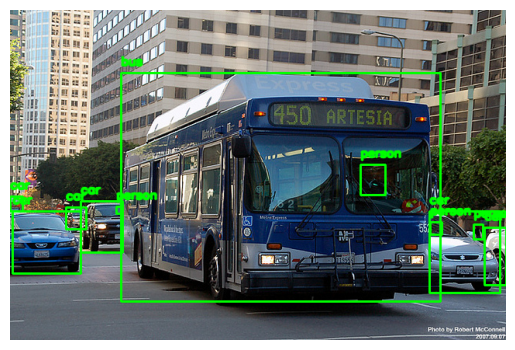

In [ ]:
show_image(train_dataset2[18])

#### Iter

In [ ]:
# Get a batch of images and labels from the data loader
examples = iter(train_loader)
images, labels = next(examples)


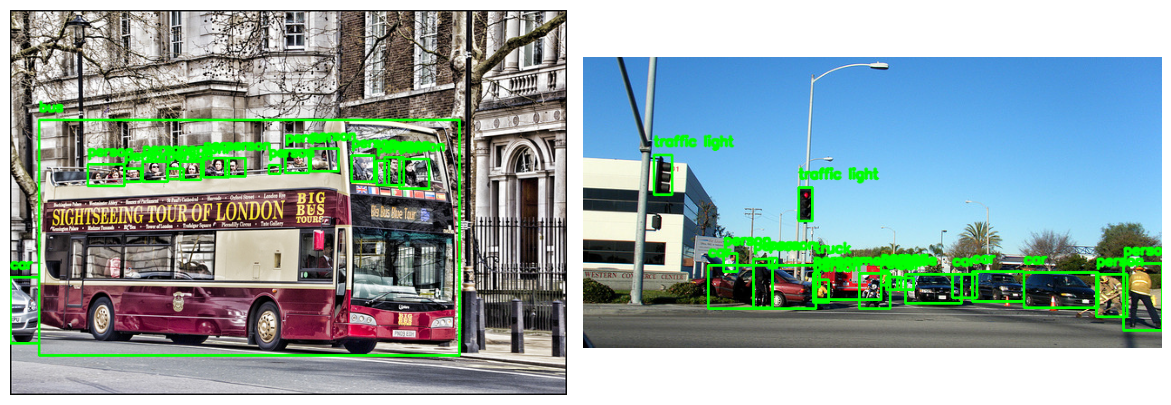

In [ ]:
show_images(images, labels, figsize=(15, 5))